# Imports

In [1]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
from torch.utils.data import Dataset

from torch.utils.data import DataLoader
import random
import seaborn as sns

from torch.nn.utils.rnn import pad_sequence
import torch
from torch.utils.data import Dataset
import random
import torch
import torch.nn as nn
import math
import matplotlib.pyplot as plt
import pandas as pd
import os
from PIL import Image
import glob

In [2]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Dataset

In [3]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df.head(2)

(15643, 11)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.116, 0.05]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]",COQVSOAUMTUPMTASCRFN,257,0.268828,256.0,1
1,0.45,"[0.143, 0.092]",0.064938,"[0.10024711755413862, 0.1422307007613116]",-0.841585,"[0.5717389806063935, 0.8204355782480194]",SOAUCOQVMTUPMTASCRFN,789,0.825314,257.0,1


In [4]:
token_to_ps = {pid:ps for pid, ps in zip(df['position_state_id'], df['position_state'])}
ps_to_token = {ps:pid for pid, ps in zip(df['position_state_id'], df['position_state'])}

In [5]:
df['position_state_id'].nunique()

954

In [6]:
df['apd_position_state_id'] = [val for val in df['position_state_id']]

In [7]:
df['position_state_id'] = df.groupby('apd_position_state_id').transform('ngroup')

In [9]:
apd_to_df_ps_id = {k:v for k, v in zip(df['apd_position_state_id'], df['position_state_id'])}
df_to_apd_ps_id = {v:k for k, v in zip(df['apd_position_state_id'], df['position_state_id'])}

In [8]:
df['position_state_id'].describe()

count    15643.000000
mean       471.705236
std        273.779721
min          0.000000
25%        236.000000
50%        466.000000
75%        706.500000
max        953.000000
Name: position_state_id, dtype: float64

<Axes: xlabel='position_state_id', ylabel='Count'>

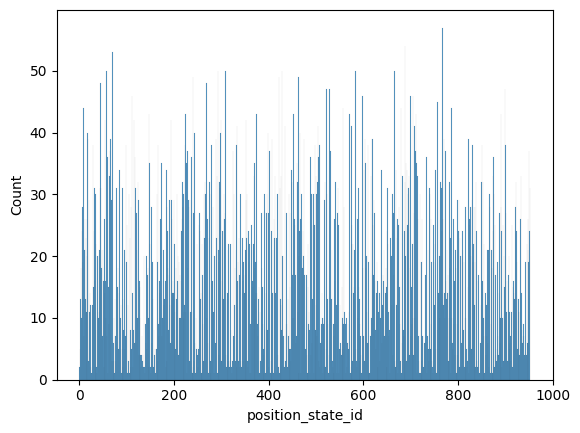

In [10]:
sns.histplot(df, x='position_state_id', binwidth=1)#.value_counts(normalize=True).hist(grid=False, )

<Axes: >

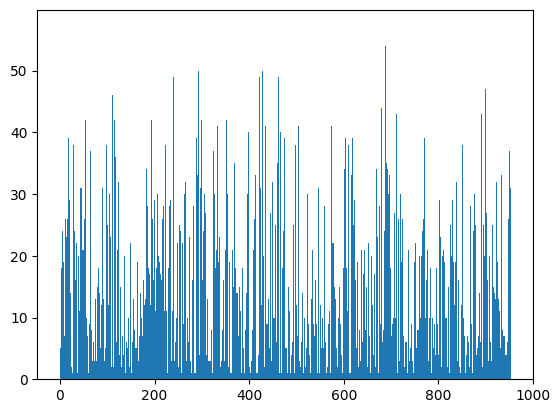

In [11]:
df['position_state_id'].hist(grid=False, bins=range(df['position_state_id'].nunique()))

## tokenized dataset

In [12]:
df['position_state_id'].head()

0    224
1    704
2    711
3    598
4    609
Name: position_state_id, dtype: int64

# Classes

In [13]:
def collate_masked_batch(batch, pad_token_id=0):
    """
    Recebe uma lista de (input_ids, target_ids) e aplica padding para o maior comprimento.
    """
    input_ids, target_ids = zip(*batch)
    
    input_ids_padded = pad_sequence(input_ids, batch_first=True, padding_value=pad_token_id)
    target_ids_padded = pad_sequence(target_ids, batch_first=True, padding_value=-100)  # ignorado pela loss

    return input_ids_padded, target_ids_padded


### dataset class

In [87]:
class TrajectoryMaskingDataset(Dataset):
    def __init__(self, full_sequence, mask_token_id, min_len=3, max_len=15, mask_prob=0.3):
        """
        full_sequence: lista 1D com todos os tokens da trajetória completa (ex: [12, 32, 99, ...])
        mask_token_id: ID reservado para o token [MASK]
        min_len, max_len: tamanho aleatório da janela de corte
        mask_prob: probabilidade de mascarar um token intermediário
        """
        self.full_sequence = full_sequence
        self.mask_token_id = mask_token_id
        self.min_len = min_len
        self.max_len = max_len
        self.mask_prob = mask_prob

        # Gera os índices de início para as janelas baseando-se no menor comprimento possível
        self.start_indices = list(range(0, len(full_sequence) - min_len))

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start = self.start_indices[idx]
        seq_len = random.randint(self.min_len, self.max_len)
        end = min(start + seq_len, len(self.full_sequence))

        seq = self.full_sequence[start:end]

        input_ids = []
        target_ids = []

        for i, token in enumerate(seq):
            if i == 0 or i == len(seq) - 1:
                input_ids.append(token)
                target_ids.append(-100)
            elif random.random() < self.mask_prob:
                input_ids.append(self.mask_token_id)
                target_ids.append(token)
            else:
                input_ids.append(token)
                target_ids.append(-100)

        return torch.tensor(input_ids, dtype=torch.long), torch.tensor(target_ids, dtype=torch.long)


In [88]:
class TrajectoryBERT(nn.Module):
    def __init__(self, vocab_size, embed_size, num_layers, num_heads, hidden_dim, dropout=0.1, max_len=512, pad_token_id=0):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.position_embedding = nn.Embedding(max_len, embed_size)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size,
            nhead=num_heads,
            dim_feedforward=hidden_dim,
            dropout=dropout,
            batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    def forward(self, x):
        """
        x: [batch_size, seq_len] tensor de input_ids (com paddings, [MASK], etc.)
        """
        batch_size, seq_len = x.size()
        device = x.device

        # Gera posições e aplica embedding
        positions = torch.arange(seq_len, device=device).unsqueeze(0).expand(batch_size, seq_len)
        x_embed = self.embedding(x) + self.position_embedding(positions)

        # Gera attention_mask para ignorar os pads
        attention_mask = (x == self.pad_token_id)  # shape: [batch_size, seq_len], bool
        # -> Transformer usa True para ignorar posições (inverso do HuggingFace)

        # Aplica encoder
        encoded = self.encoder(x_embed, src_key_padding_mask=attention_mask)
        logits = self.fc_out(encoded)

        return logits

In [89]:
def _range_check(x, y, vocab_size, where="train"):
    if (x.dtype != torch.long) or (y.dtype != torch.long):
        raise TypeError(f"[{where}] dtype errado: x={x.dtype}, y={y.dtype}; use torch.long")

    x_min = int(x.min().item()); x_max = int(x.max().item())
    y_min = int(y[y != -100].min().item()) if torch.any(y != -100) else 0
    y_max = int(y[y != -100].max().item()) if torch.any(y != -100) else 0

    if x_min < 0 or x_max >= vocab_size:
        bad = x[(x < 0) | (x >= vocab_size)]
        raise ValueError(f"[{where}] x fora do range 0..{vocab_size-1}. min={x_min}, max={x_max}. Exemplos: {bad[:10].tolist()}")

    if torch.any((y != -100) & ((y < 0) | (y >= vocab_size))):
        bad = y[(y != -100) & ((y < 0) | (y >= vocab_size))]
        raise ValueError(f"[{where}] y fora do range 0..{vocab_size-1} (exceto -100). min={y_min}, max={y_max}. Exemplos: {bad[:10].tolist()}")


# Definitions

In [90]:
# Hiperparâmetros
embed_size = 256
num_layers = 2
num_heads = 2
hidden_dim = 512
mask_token_id = df['position_state_id'].max()
pad_token_id = df['position_state_id'].max() + 1
vocab_size = pad_token_id + 1
seq_length = 7
dropout = 0.3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 30
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 955)

In [91]:
sequences

array([224, 704, 711, ..., 146, 148, 111])

In [92]:
# df['position_state_id'].describe()

In [93]:
mask_token_id, pad_token_id

(953, 954)

In [94]:
# mask_token_id = 469 + 1  # ou qualquer valor fora do intervalo real
# pad_token_id = 4         # se 0 não for usado no vocabulário real

# dataset = TrajectoryMaskingDataset(sequences, mask_token_id , max_len=seq_length)
# loader = DataLoader(dataset, batch_size=16, shuffle=True, collate_fn=lambda x: collate_masked_batch(x, pad_token_id))

In [95]:
# for x, y in loader:
#     print("Input shape:", x.shape)
#     print("Target shape:", y.shape)
#     print("Input:", x[0])
#     print("Target:", y[0])
#     break

In [96]:
# # 0) Verifique dados
# assert np.min(sequences) >= 0, "Há IDs negativos no dataset!"

# # 1) IDs especiais e vocabulário
# data_max = int(np.max(sequences))
# mask_token_id = data_max + 1
# pad_token_id  = mask_token_id + 1
# vocab_size = pad_token_id + 1  # cobre [0..data_max], mask e pad

# # 2) Dataset/Loaders usam os MESMOS IDs
# dataset = TrajectoryMaskingDataset(sequences, mask_token_id,)
# train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
#                           collate_fn=lambda b: collate_masked_batch(b, pad_token_id), num_workers=0)
# val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False,
#                           collate_fn=lambda b: collate_masked_batch(b, pad_token_id), num_workers=0)

# # 3) Modelo com padding_idx
# model = TrajectoryBERT(vocab_size, embed_size, num_layers, num_heads, hidden_dim,
#                        dropout=0.1, pad_token_id=pad_token_id).to(device)

# # 4) Antes de rodar cada batch
# _range_check(x, y, vocab_size, "train/val")


In [97]:
np.max(sequences)

953

In [98]:
# Dataset e dataloaders
dataset = TrajectoryMaskingDataset(sequences, mask_token_id)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size 
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

In [99]:
# Inicialização do modelo e treino
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = TrajectoryBERT(vocab_size, embed_size=embed_size, num_layers=num_layers, num_heads=num_heads, hidden_dim=hidden_dim,
                       dropout=dropout, pad_token_id=pad_token_id).to(device)

In [100]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss(ignore_index=-100)

In [101]:
train_losses = []
val_losses = []
train_perplexities = []
val_perplexities = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          collate_fn=lambda x: collate_masked_batch(x, pad_token_id))
    
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False,
                        collate_fn=lambda x: collate_masked_batch(x, pad_token_id))
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        output = model(x)
        loss = criterion(output.view(-1, vocab_size), y.view(-1))
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val, y_val = x_val.to(device), y_val.to(device)
            val_output = model(x_val)
            v_loss = criterion(val_output.view(-1, vocab_size), y_val.view(-1))
            val_loss += v_loss.item()

    # Cálculo médio das perdas
    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    # Cálculo da perplexidade
    train_ppl = math.exp(avg_train_loss)
    val_ppl = math.exp(avg_val_loss)

    # Armazenamento
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    train_perplexities.append(train_ppl)
    val_perplexities.append(val_ppl)

    if (epoch + 1) % max(1, num_epochs // 10) == 0 or (epoch + 1) == num_epochs:
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | "
            f"Train PPL: {train_ppl:.2f} | Val PPL: {val_ppl:.2f}")


Epoch 3/30 | Train Loss: 5.6889 | Val Loss: 4.8397 | Train PPL: 295.58 | Val PPL: 126.43
Epoch 6/30 | Train Loss: 3.2269 | Val Loss: 2.5099 | Train PPL: 25.20 | Val PPL: 12.30
Epoch 9/30 | Train Loss: 2.2042 | Val Loss: 1.7334 | Train PPL: 9.06 | Val PPL: 5.66
Epoch 12/30 | Train Loss: 1.7840 | Val Loss: 1.3912 | Train PPL: 5.95 | Val PPL: 4.02
Epoch 15/30 | Train Loss: 1.5227 | Val Loss: 1.1811 | Train PPL: 4.58 | Val PPL: 3.26
Epoch 18/30 | Train Loss: 1.3680 | Val Loss: 1.0973 | Train PPL: 3.93 | Val PPL: 3.00
Epoch 21/30 | Train Loss: 1.2743 | Val Loss: 0.9822 | Train PPL: 3.58 | Val PPL: 2.67
Epoch 24/30 | Train Loss: 1.1714 | Val Loss: 0.9418 | Train PPL: 3.23 | Val PPL: 2.56
Epoch 27/30 | Train Loss: 1.1316 | Val Loss: 0.8584 | Train PPL: 3.10 | Val PPL: 2.36
Epoch 30/30 | Train Loss: 1.0686 | Val Loss: 0.8178 | Train PPL: 2.91 | Val PPL: 2.27


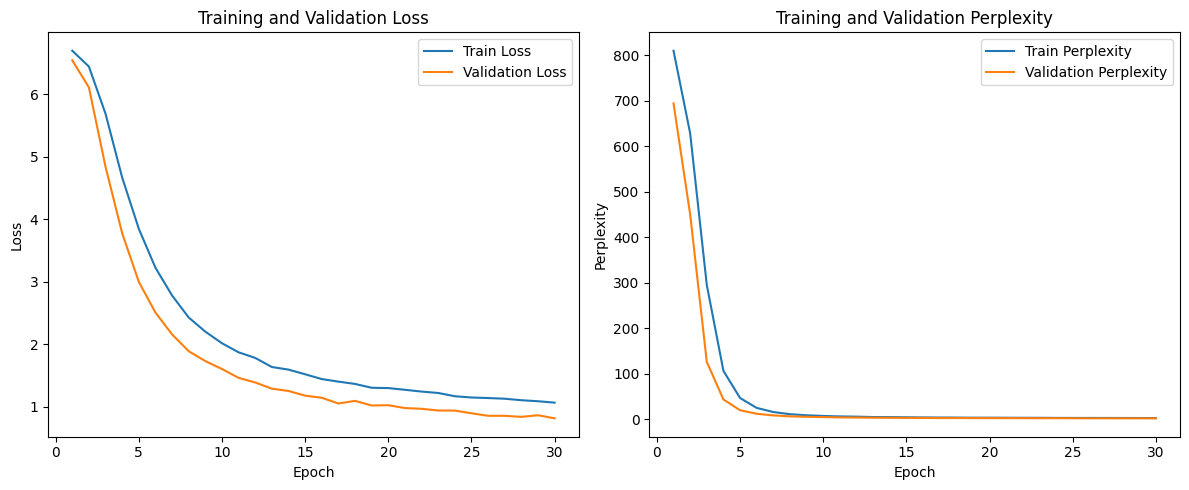

In [102]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
# plt.grid(True)

plt.tight_layout()
plt.show()


# Vizz Predictions

In [103]:
def visualize_predictions(model, x, y, mask_token_id, id_to_token=None):
    """
    Exibe a entrada x, os targets y e as previsões do modelo nas posições mascaradas.
    """
    if id_to_token is None:
        id_to_token = {}

    model.eval()
    device = next(model.parameters()).device
    x = x.unsqueeze(0).to(device)
    y = y.to(device)

    with torch.no_grad():
        logits = model(x)
        preds = torch.argmax(logits, dim=-1).squeeze(0).cpu()

    x = x.squeeze(0).cpu()
    y = y.cpu()

    # Vetor de entrada
    entrada_str = [id_to_token.get(tok.item(), str(tok.item())) for tok in x]
    target_str = [
        id_to_token.get(t.item(), str(t.item())) if t.item() != -100 else '-' for t in y
    ]
    pred_str = [
        id_to_token.get(t.item(), str(t.item())) if t.item() != -100 else '-' for t in preds
    ]

    print("\nEntrada (x):")
    print("[" + " ".join(entrada_str) + "]")

    print("\nTarget (y_hat):")
    print("[" + " ".join(target_str) + "]\n")

    print("\nPredição (y):")
    print("[" + " ".join(pred_str) + "]\n")

    print(f"{'Posição':<8} {'Token em x':<14} {'Esperado (y)':<20} {'Previsto':<20} {'Correto'}")
    print("-" * 80)

    for i in range(len(x)):
        if y[i].item() == -100:
            continue

        input_token_id = x[i].item()
        target_token_id = y[i].item()
        predicted_token_id = preds[i].item()

        input_token = id_to_token.get(input_token_id, str(input_token_id))
        target_token = id_to_token.get(target_token_id, str(target_token_id))
        predicted_token = id_to_token.get(predicted_token_id, str(predicted_token_id))

        correto = "SIM" if target_token_id == predicted_token_id else "NÃO"
        print(f"{i:<8} {input_token:<14} {target_token:<20} {predicted_token:<20} {correto}")
    print("-" * 80)


In [104]:
mask_token_id

953

In [106]:
x_batch, y_batch = next(iter(val_loader))
example_x = x_batch[0]
example_y = y_batch[0]

visualize_predictions(model, example_x, example_y, mask_token_id)


Entrada (x):
[226 240 226 374 953 399 954 954 954 954 954 954 954 954 954]

Target (y_hat):
[- - - - 401 - - - - - - - - - -]


Predição (y):
[401 228 226 228 401 226 918 918 918 918 918 918 918 918 918]

Posição  Token em x     Esperado (y)         Previsto             Correto
--------------------------------------------------------------------------------
4        953            401                  401                  SIM
--------------------------------------------------------------------------------


In [76]:
example_x

tensor([503, 504, 570, 568, 598, 954, 954, 954, 954, 954, 954, 954, 954, 954,
        954])

In [80]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import cm

def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = cm.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="best")

    # Não chama plt.show(); quem usa decide salvar/mostrar


In [81]:
def gerar_graficos_expansao(apd, sequencias_ids, pasta_destino="imgs", titulo_base="Passo", dpi=150):
    """
    Gera e salva gráficos por etapas, pintando as regiões em função da lista de ids recebida.
    NÃO executa modelo; apenas plota conforme as sequências fornecidas.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - sequencias_ids: lista de listas de ids (ex.: [[s,e], [s,x,e], [s,x,y,e], ...])
                      Cada sublista é um "passo" do GIF.
    - pasta_destino: pasta onde os PNGs serão salvos
    - titulo_base: prefixo do título (ex.: "Passo")
    - dpi: resolução dos PNGs

    Retorna:
    - lista com os caminhos dos arquivos gerados
    """
    if not isinstance(sequencias_ids, (list, tuple)) or len(sequencias_ids) == 0:
        raise ValueError("sequencias_ids deve ser uma lista não vazia de listas de ids.")

    os.makedirs(pasta_destino, exist_ok=True)
    caminhos = []

    for step, ids in enumerate(sequencias_ids):
        if not isinstance(ids, (list, tuple)) or len(ids) == 0:
            raise ValueError(f"Item na posição {step} de sequencias_ids não é uma lista/tupla válida de ids.")

        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")

        # usa a função definida antes no chat (com viridis, ordem por ids,
        # último em destaque, anotações pretas)
        title = f"{titulo_base} {step:02} | {ids[0]}->{ids[-1]}" if len(ids) >= 2 else f"{titulo_base} {step:02}"
        plot_position_states_w_title(apd, grupos_destacados=list(ids), title=title)

        plt.savefig(caminho_arquivo, bbox_inches="tight", dpi=dpi)
        plt.close()
        caminhos.append(caminho_arquivo)

    return caminhos


In [32]:
def expand_trajectory(model, start_token, end_token, mask_token_id, max_len=12, id_to_token=None):
    """
    Expande uma sequência entre start_token e end_token, preenchendo iterativamente
    tokens intermediários e mostrando o histórico de predições.
    """
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    step = 1

    while len(sequence) < max_len:
        print(f"\n=== Etapa {step} ===")
        print("Sequência atual:", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Inserção de MASKs entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        print("Com [MASK]:     ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()
            print('Predição Completa', predictions)

        # Substituição dos MASKs e exibição
        updated_sequence = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                print(f"Predição na posição {i}: {id_to_token.get(predicted_token, predicted_token) if id_to_token else predicted_token}")
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print("Após predição: ", [id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])

        if len(sequence) >= max_len:
            print("\nLimite de comprimento atingido.")
            break

        step += 1

    print("\n=== Trajetória Final ===")
    print([id_to_token.get(t, str(t)) if id_to_token else t for t in sequence])
    return sequence


In [33]:
np.random.choice(sequences, 2)

array([507, 715])

In [34]:
start_token = 507
end_token = 715
# max_len = 15

In [35]:
expand_trajectory(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    # max_len=max_len,
    # id_to_token=id_to_token  # ou None
)


=== Etapa 1 ===
Sequência atual: [507, 715]
Com [MASK]:      [507, 953, 715]
Predição Completa [799, 501, 582]
Predição na posição 1: 501
Após predição:  [507, 501, 715]

=== Etapa 2 ===
Sequência atual: [507, 501, 715]
Com [MASK]:      [507, 953, 501, 953, 715]
Predição Completa [332, 583, 583, 340, 716]
Predição na posição 1: 583
Predição na posição 3: 340
Após predição:  [507, 583, 501, 340, 715]

=== Etapa 3 ===
Sequência atual: [507, 583, 501, 340, 715]
Com [MASK]:      [507, 953, 583, 953, 501, 953, 340, 953, 715]
Predição Completa [507, 501, 507, 507, 507, 507, 507, 501, 330]
Predição na posição 1: 501
Predição na posição 3: 507
Predição na posição 5: 507
Predição na posição 7: 501
Após predição:  [507, 501, 583, 507, 501, 507, 340, 501, 715]

=== Etapa 4 ===
Sequência atual: [507, 501, 583, 507, 501, 507, 340, 501, 715]
Com [MASK]:      [507, 953, 501, 953, 583, 953, 507, 953, 501, 953, 507, 953, 340, 953, 501, 953, 715]
Predição Completa [507, 583, 340, 507, 507, 501, 507, 34

[507,
 583,
 501,
 507,
 583,
 501,
 507,
 340,
 501,
 507,
 507,
 501,
 340,
 507,
 501,
 501,
 715]

In [37]:
apd = pd.read_parquet(r'legacy/datasets/apd_full.gzip')
apd.shape

(1002001, 80)

In [43]:
df_ps_to_apd_id = {ps:idx for ps, idx in zip(df['position_state'], df['position_state_id'])}

In [46]:
df['position_state_id'].max()

953

In [48]:
count = 0
current_max_id = df['position_state_id'].max() + 1
for apd_ps in apd['position_state'].unique():
    if apd_ps not in df_ps_to_apd_id:
        df_ps_to_apd_id[apd_ps]  = current_max_id
        current_max_id+=1
        count+=1
print(count)

0


In [50]:
apd['position_state_id'] = [df_ps_to_apd_id[ps] for ps in apd['position_state']]

In [55]:
apd['position_state_id'].nunique()

1057

In [86]:
x_batch, y_batch = next(iter(val_loader))
example_x = x_batch[0]
example_y = y_batch[0]

visualize_predictions(model, example_x, example_y, mask_token_id)


Entrada (x):
[503 953 570 953 598 954 954 954 954 954 954 954 954 954 954]

Target (y_hat):
[- 504 - 568 - - - - - - - - - - -]


Predição (y):
[511 504 499 511 511 564 564 564 564 564 564 564 564 564 564]

Posição  Token em x     Esperado (y)         Previsto             Correto
--------------------------------------------------------------------------------
1        953            504                  504                  SIM
3        953            568                  511                  NÃO
--------------------------------------------------------------------------------


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


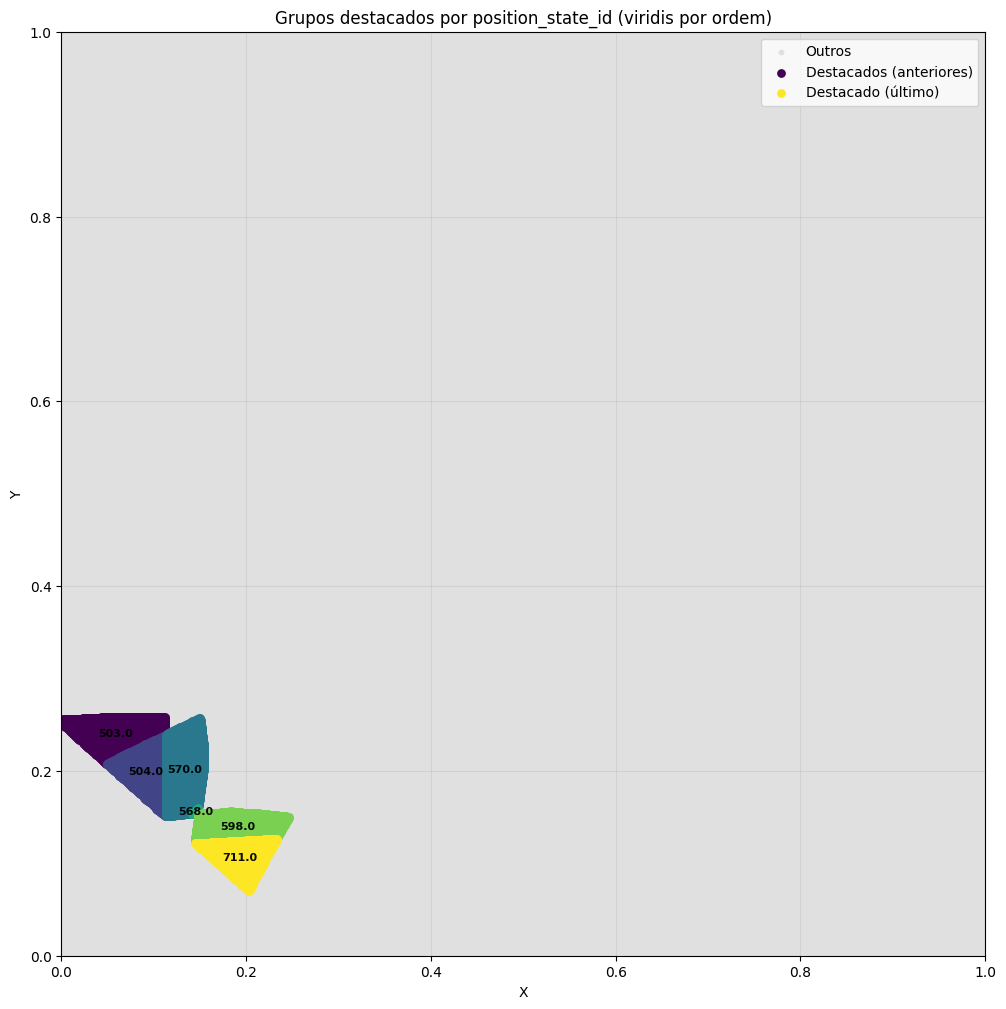

In [85]:
plot_position_states_w_title(apd, [503, 504, 570, 568, 598, 711])

In [ ]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()

In [ ]:
def plot_position_states_w_region(apd, region):
    """
    Plota os pontos do DataFrame apd, destacando grupos (position_state_id)
    que possuem pontos dentro da região [xmin, xmax, ymin, ymax].

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - region: lista ou tupla com [xmin, xmax, ymin, ymax]
    """
    xmin, xmax, ymin, ymax = region

    # Filtrar os pontos que estão dentro da região
    dentro = apd[(apd['X'] >= xmin) & (apd['X'] <= xmax) &
                 (apd['Y'] >= ymin) & (apd['Y'] <= ymax)]

    # Identificar os grupos que têm pelo menos um ponto na região
    grupos_destacados = dentro['position_state_id'].unique()
    print('Grupos Destados', grupos_destacados)

    # Máscara dos grupos destacados
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Plot
    plt.figure(figsize=(12, 12))

    # Pontos não destacados (fundo)
    cor_base = '#e0e0e0'
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Pontos destacados (na região)
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar centro de massa de cada grupo destacado
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Colorbar
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Desenhar a região no gráfico
    plt.plot([xmin, xmax, xmax, xmin, xmin],
             [ymin, ymin, ymax, ymax, ymin], color='black', linestyle='--', linewidth=1.2, label='Região')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por interseção com região')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()

Grupos Destados [891 892 902 899]


/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


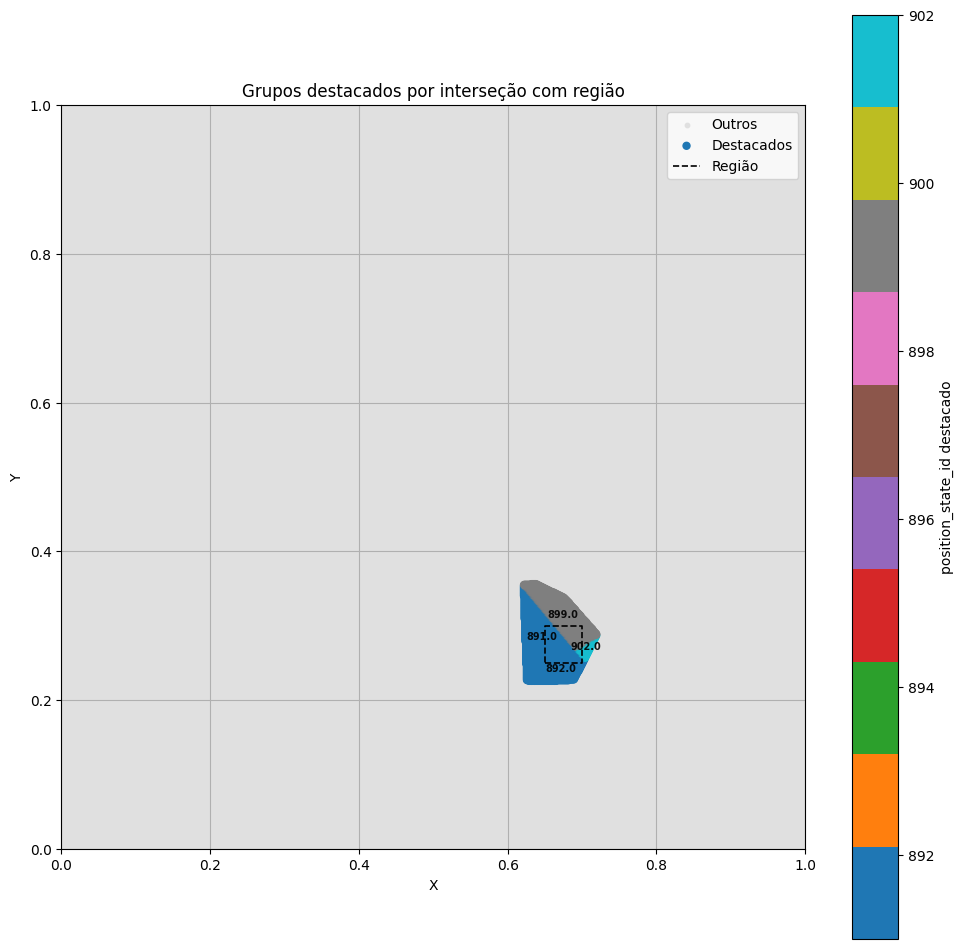

In [56]:
plot_position_states_w_region(apd, region=[0.65, 0.7, 0.25, 0.3])

/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


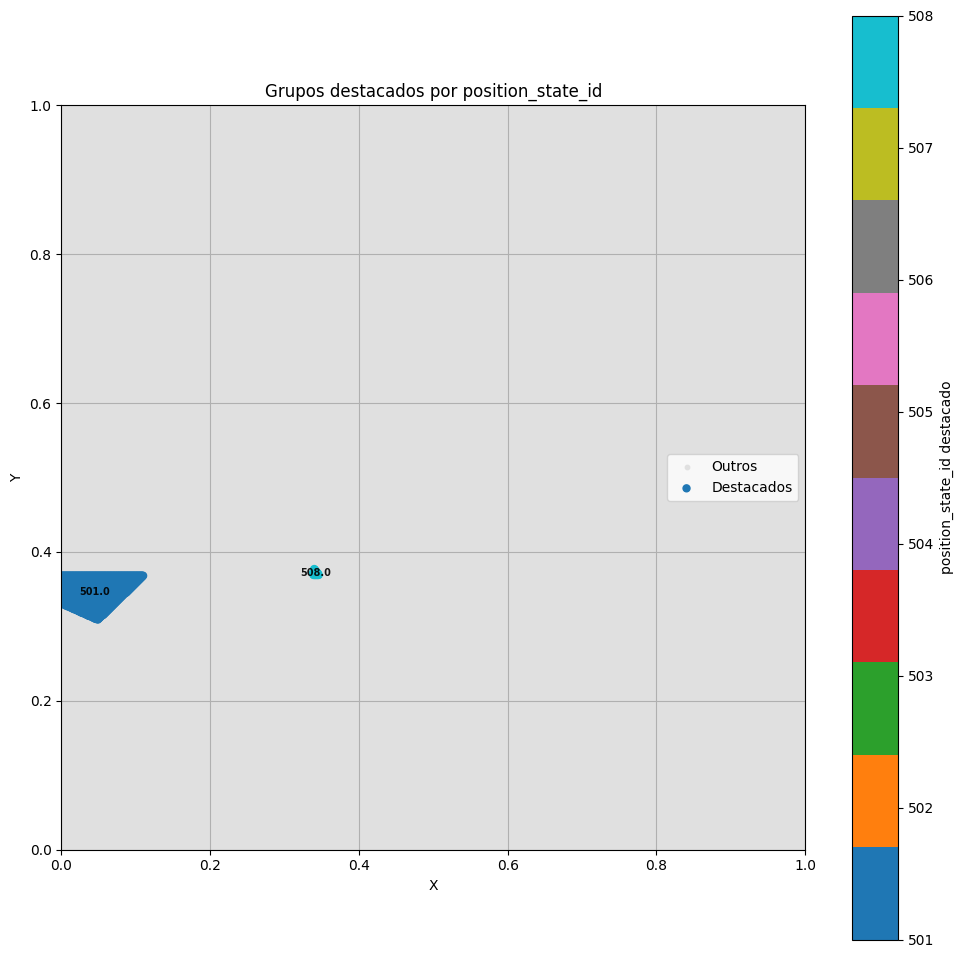

In [54]:
plot_position_states(apd, [501, 508])

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


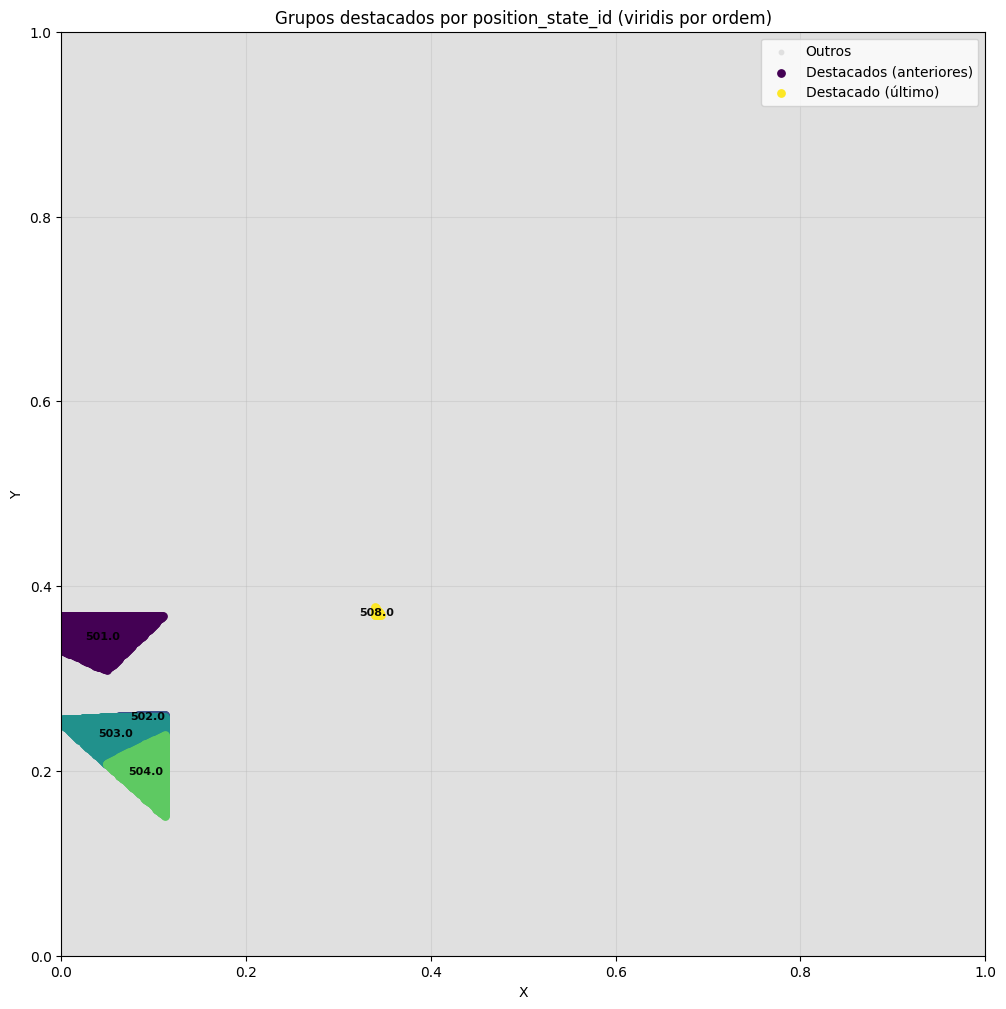

In [72]:
plot_position_states_w_title(apd, [501,502, 503, 504, 508])

In [63]:
def gerar_graficos_expansao(model, start_token, end_token, mask_token_id,
                             max_len,  apd, pasta_destino="imgs"):
    """
    Executa a expansão da trajetória e salva os gráficos das etapas destacando os grupos preditos.

    Parâmetros:
    - model: modelo de linguagem
    - start_token, end_token, mask_token_id, pad_token_id: tokens especiais
    - max_len: tamanho máximo da sequência
    - id_to_token: dicionário de id para string
    - apd: DataFrame com colunas 'X', 'Y', 'position_state_id'
    - pasta_destino: pasta onde os gráficos serão salvos
    """
    os.makedirs(pasta_destino, exist_ok=True)
    step = 0
    # Salva gráfico com os novos IDs destacados
    caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
    device = next(model.parameters()).device
    sequence = [start_token, end_token]
    plot_position_states_w_title(apd, grupos_destacados=sequence, title=f"Passo {step:02} | {sequence[0]}->{sequence[1]}")
    plt.savefig(caminho_arquivo)
    plt.close()
    step +=1
    

    while len(sequence) < max_len:
        # Inserir [MASK] entre os pares
        new_sequence = []
        for i in range(len(sequence) - 1):
            new_sequence.append(sequence[i])
            new_sequence.append(mask_token_id)
        new_sequence.append(sequence[-1])
        sequence = new_sequence

        # Predição
        input_tensor = torch.tensor(sequence, dtype=torch.long).unsqueeze(0).to(device)
        with torch.no_grad():
            logits = model(input_tensor)
            predictions = torch.argmax(logits, dim=-1).squeeze(0).cpu().tolist()

        # Substituição dos MASKs
        updated_sequence = []
        novos_ids = []
        for i, token in enumerate(sequence):
            if token == mask_token_id:
                predicted_token = predictions[i]
                updated_sequence.append(predicted_token)
                novos_ids.append(predicted_token)
            else:
                updated_sequence.append(token)

        sequence = updated_sequence
        print(sequence)
        
        # print(novos_ids)
        caminho_arquivo = os.path.join(pasta_destino, f"etapa_{step:02}.png")
        plot_position_states_w_title(apd, grupos_destacados=updated_sequence, title=f"Passo {step:02}")
        plt.savefig(caminho_arquivo)
        plt.close()

        if len(sequence) >= max_len:
            break
        step += 1

    return


In [64]:
start_token = 501
end_token = 508
max_len = 20

In [73]:
gerar_graficos_expansao(
    model,
    start_token=start_token,
    end_token=end_token,
    mask_token_id=mask_token_id,
    max_len=max_len,
    apd=apd
)

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 507, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 583, 507, 501, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


...

/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 583, 507, 501, 583, 507, 501, 583, 507, 583, 505, 507, 501, 507, 500, 340, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


[501, 507, 583, 501, 507, 505, 501, 507, 583, 507, 507, 340, 501, 507, 583, 501, 507, 507, 583, 501, 505, 501, 507, 501, 501, 501, 507, 501, 500, 505, 340, 507, 508]


/tmp/ipykernel_1050/2161532076.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(cmap_name, max(n, 2))


In [60]:
def gerar_gif(pasta_imagens, nome_gif='legacy/media/trajetoria_animada.gif', duracao=1000):
    """
    Gera um GIF animado com os gráficos salvos.

    Parâmetros:
    - pasta_imagens: pasta onde estão os arquivos PNG
    - nome_gif: nome do arquivo de saída
    - duracao: duração entre os frames (em ms)
    """
    arquivos = sorted(glob.glob(os.path.join(pasta_imagens, "*.png")))
    imagens = [Image.open(arquivo) for arquivo in arquivos]

    if imagens:
        imagens[0].save(nome_gif, save_all=True, append_images=imagens[1:], duration=duracao, loop=0)
        print(f"GIF salvo como {nome_gif}")
    else:
        print("Nenhuma imagem encontrada para criar o GIF.")

In [61]:
# filepaths
fp_in = r"imgs/*.png"
fp_out = "legacy/media/gif_s25.gif"

# # # https://pillow.readthedocs.io/en/stable/handbook/image-file-formats.html#gif
img, *imgs = [Image.open(f) for f in sorted(glob.glob(fp_in))]
img.save(fp=fp_out, format='GIF', append_images=imgs,
         save_all=True, duration=500, loop=0)   

In [59]:
for i in sorted(glob.glob(fp_in)):
    print(i)

imgs/etapa_00.png
imgs/etapa_01.png
imgs/etapa_02.png
imgs/etapa_03.png
imgs/etapa_04.png


In [54]:
gerar_gif('imgs/', )

GIF salvo como trajetoria_animada.gif
